# Day 62 — CV Project Chest X-ray Pneumonia Classifier (Educational only)

**Goal:** Build an end-to-end image-classification project using transfer learning, then evaluate it with special attention to pneumonia recall and false negatives.

## 1. What you will learn

- Load a folder-based image dataset with explicit class labels.
- Use a pretrained **MobileNetV2** model as a feature extractor.
- Handle class imbalance with class weights.
- Measure **recall / sensitivity**, specificity, precision, F1, and the precision–recall curve.
- Choose an educational decision threshold using the validation split—not the test set.
- Inspect false negatives and false positives instead of reporting accuracy alone.
- Save the model and a small metadata file for a portfolio demo.

**Positive class convention:** `PNEUMONIA = 1`; `NORMAL = 0`. Recall for the positive class answers: “Of all images labelled pneumonia in this evaluation set, what fraction did the model mark as pneumonia?”

## 2. Environment setup
The model is small enough for many CPU setups, but training may still take time. Start with fewer epochs if needed. A GPU is optional.

In [1]:
# Imports and reproducibility
from pathlib import Path
import json
import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Visible GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.4.6
Visible GPUs: []


## 3. Dataset download and folder setup

Download the **Chest X-Ray Images (Pneumonia)** dataset from Kaggle:

- Dataset page: <https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia>
- The commonly circulated archive contains `train`, `test`, and `val` folders, each with `NORMAL` and `PNEUMONIA` subfolders.
- Read the dataset page and licence terms yourself before redistributing data or using it outside this learning project. Cite Kermany et al. (2018) in your project description.

Extract the archive. The dataset root should contain a structure like this:

```text
chest_xray/
├── train/
│   ├── NORMAL/
│   └── PNEUMONIA/
├── test/
│   ├── NORMAL/
│   └── PNEUMONIA/
└── val/                 # may be extremely small in the commonly shared archive
    ├── NORMAL/
    └── PNEUMONIA/
```

**Important split decision:** this notebook makes a validation split from `train` and leaves `test` for final evaluation. It does **not** use the tiny provided `val` folder. Do not tune your model repeatedly against the test set. If reliable patient identifiers are available, split by patient—not by image—and check for duplicate or near-duplicate images across splits.

In [2]:
# EDIT THIS PATH if needed. It may point to the extracted dataset folder OR its parent folder.
# Windows example: Path(r"C:\Users\YourName\Downloads\chest_xray")
# DATA_ROOT = Path.home() / "Downloads" / "chest_xray"
DATA_ROOT = Path(r"C:\Users\Puneeth\Downloads\chest_xray")  # <-- EDIT THIS PATH if needed
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]  # explicit order: 0 = NORMAL, 1 = PNEUMONIA
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
VALIDATION_SPLIT = 0.15
EPOCHS = 5
TARGET_RECALL = 0.95  # educational target only; NOT a clinical standard
AUTOTUNE = tf.data.AUTOTUNE

# Find common extraction layouts without scanning the whole disk.
def resolve_dataset_root(path: Path) -> Path | None:
    path = Path(path).expanduser()
    candidates = [
        path,
        path / "chest_xray",
        path / "Chest-Xray-Pneumonia",
        path / "chest_xray" / "chest_xray",
    ]
    for candidate in candidates:
        if (candidate / "train").is_dir() and (candidate / "test").is_dir():
            return candidate
    return None

DATA_DIR = resolve_dataset_root(DATA_ROOT)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find train/ and test/ folders. Edit DATA_ROOT in this cell so it points "
        "to the extracted dataset folder or its parent. Example: Path(r'C:\\Users\\YourName\\Downloads\\chest_xray')."
    )

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
print("Dataset root:", DATA_DIR)
print("Train folder exists:", TRAIN_DIR.is_dir())
print("Test folder exists:", TEST_DIR.is_dir())
for split_dir in [TRAIN_DIR, TEST_DIR]:
    missing = [name for name in CLASS_NAMES if not (split_dir / name).is_dir()]
    if missing:
        raise FileNotFoundError(f"Missing class folders in {split_dir}: {missing}")

Dataset root: C:\Users\Puneeth\Downloads\chest_xray
Train folder exists: True
Test folder exists: True


## 4. Inspect class counts before training

Class imbalance matters: a model can obtain apparently good accuracy by favouring the more common class. First count the image files and view a small sample. This is a basic folder audit, not a guarantee that labels or patient-level splits are correct.

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def list_class_images(split_dir: Path, class_names=CLASS_NAMES):
    rows = []
    paths_by_class = {}
    for class_name in class_names:
        paths = sorted(
            p for p in (split_dir / class_name).rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        paths_by_class[class_name] = paths
        rows.append({"split": split_dir.name, "class": class_name, "image_count": len(paths)})
    return pd.DataFrame(rows), paths_by_class

train_counts_df, train_paths_by_class = list_class_images(TRAIN_DIR)
test_counts_df, test_paths_by_class = list_class_images(TEST_DIR)
counts_df = pd.concat([train_counts_df, test_counts_df], ignore_index=True)
display(counts_df.pivot(index="class", columns="split", values="image_count").fillna(0).astype(int))

if any(len(train_paths_by_class[c]) == 0 for c in CLASS_NAMES):
    raise ValueError("At least one training class has no images. Check the folder names and dataset extraction.")
if any(len(test_paths_by_class[c]) == 0 for c in CLASS_NAMES):
    raise ValueError("At least one test class has no images. Check the folder names and dataset extraction.")

split,test,train
class,,
NORMAL,234,1341
PNEUMONIA,390,3875


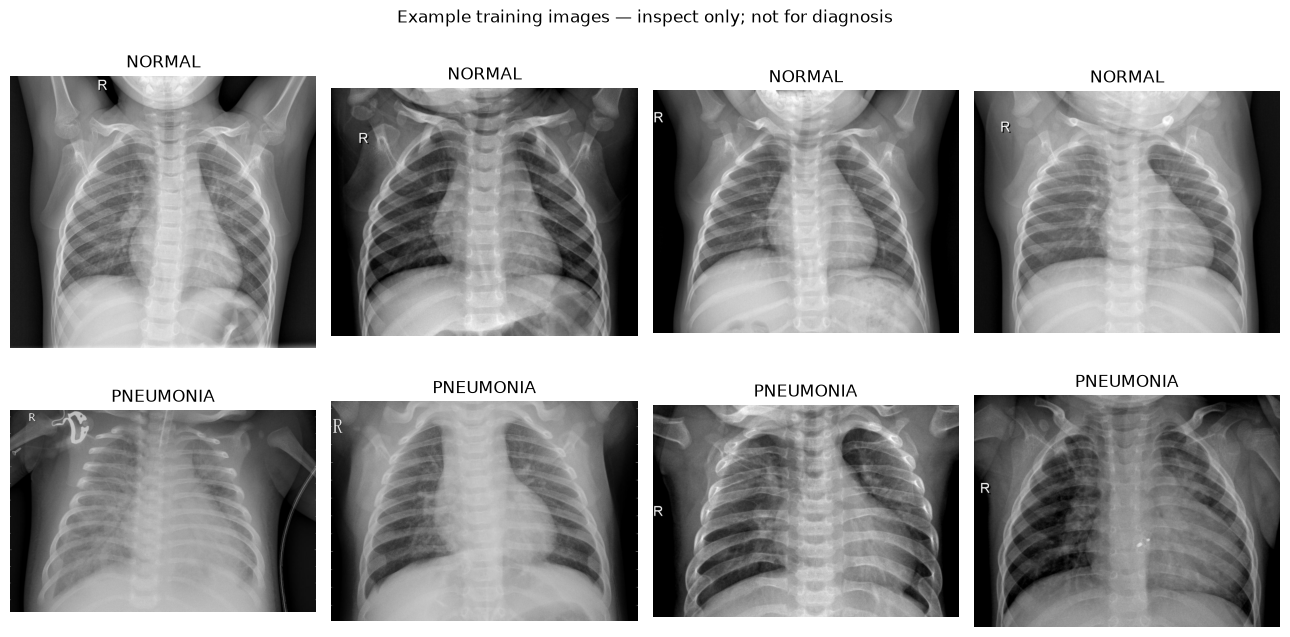

In [4]:
# Visual sample: filenames are not clinical interpretations.
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for row, class_name in enumerate(CLASS_NAMES):
    sample_paths = train_paths_by_class[class_name][:4]
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(sample_paths):
            with Image.open(sample_paths[col]) as img:
                ax.imshow(img.convert("RGB"), cmap="gray")
            ax.set_title(class_name)
plt.suptitle("Example training images — inspect only; not for diagnosis")
plt.tight_layout()
plt.show()

## 5. Build TensorFlow data pipelines

`image_dataset_from_directory` infers labels from folder names. We set `class_names` explicitly to lock in the convention that `NORMAL = 0` and `PNEUMONIA = 1`. The validation subset is selected only from the training folder; the separate test folder remains untouched until final evaluation.

The images are loaded as three-channel RGB and resized to 224×224 for MobileNetV2. The model contains its own input rescaling layer, so the data pipeline should **not** also divide images by 255.

In [5]:
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True,
    seed=SEED,
    validation_split=VALIDATION_SPLIT,
    subset="training",
)

val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=False,
    seed=SEED,
    validation_split=VALIDATION_SPLIT,
    subset="validation",
)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=False,
)

print("Detected class order:", CLASS_NAMES)
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
Detected class order: ['NORMAL', 'PNEUMONIA']


In [6]:
# Confirm image/label shapes and value range for one batch.
for batch_images, batch_labels in train_ds.take(1):
    print("Image batch shape:", batch_images.shape)
    print("Label batch shape:", batch_labels.shape)
    print("Pixel min/max before model rescaling:", float(tf.reduce_min(batch_images)), float(tf.reduce_max(batch_images)))
    print("Example labels:", batch_labels[:10].numpy().ravel().astype(int).tolist())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16, 1)
Pixel min/max before model rescaling: 0.0 255.0
Example labels: [1, 1, 1, 1, 1, 0, 0, 1, 0, 0]


## 6. Calculate class weights

Class weights make errors on the underrepresented class contribute more to the training loss. They can help but do **not** guarantee high recall, correct calibration, or improved clinical safety. We'll still measure performance on the held-out validation and test sets.

In [7]:
# Count labels in the training subset. Iterating over the dataset here does not modify the files.
y_train_for_weights = np.concatenate([
    y.numpy().ravel().astype(int) for _, y in train_ds
])
classes_in_train = np.unique(y_train_for_weights)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_in_train,
    y=y_train_for_weights,
)
class_weight = {int(cls): float(weight) for cls, weight in zip(classes_in_train, weights)}

print("Training label counts:", pd.Series(y_train_for_weights).value_counts().sort_index().rename(index={0: "NORMAL (0)", 1: "PNEUMONIA (1)"}))
print("Class weights:", class_weight)

Training label counts: NORMAL (0)       1151
PNEUMONIA (1)    3283
Name: count, dtype: int64
Class weights: {0: 1.9261511728931364, 1: 0.675296984465428}


## 7. Create the transfer-learning model

We use MobileNetV2 pretrained on ImageNet as a feature extractor and attach a small binary classification head. The backbone is frozen for the first training pass. The model emits one sigmoid score for the `PNEUMONIA` class.

ImageNet pretraining does not make this a medically validated system. A model may learn shortcuts such as image source, acquisition patterns, or dataset-specific artifacts. Avoid adding aggressive geometric augmentation by default; transformations that seem harmless for everyday photos can change medically meaningful context.

In [8]:
# Downloading ImageNet weights requires internet the first time this cell runs.
base_model = keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMAGE_SIZE, 3),
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="chest_xray_rgb")
# MobileNetV2 preprocessing maps pixels from [0, 255] to approximately [-1, 1].
x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0, name="mobilenetv2_rescaling")(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.25, name="classification_dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_score")(x)
model = keras.Model(inputs, outputs, name="chest_xray_pneumonia_demo")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy_at_0_5"),
        keras.metrics.Precision(name="precision_at_0_5"),
        keras.metrics.Recall(name="recall_at_0_5"),
        keras.metrics.AUC(name="roc_auc", curve="ROC"),
        keras.metrics.AUC(name="pr_auc", curve="PR"),
    ],
)
model.summary()

Model: "chest_xray_pneumonia_demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ chest_xray_rgb (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_rescaling           │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_dropout          │ (None, 1280)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_score (Dense)         │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 8. Train with callbacks

Early stopping restores the weights from the epoch with the best validation loss. `class_weight` is used for the training subset only. The built-in precision/recall metrics use a default threshold of 0.5; later we will calculate recall again at an explicitly selected threshold.

In [9]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6, verbose=1
    ),
]

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)
print(f"Elapsed training time: {(time.time() - start_time) / 60:.1f} minutes")

Epoch 1/5


c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


278/278 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy_at_0_5: 0.8771 - loss: 0.2808 - pr_auc: 0.9844 - precision_at_0_5: 0.9594 - recall_at_0_5: 0.8708 - roc_auc: 0.9573 - val_accuracy_at_0_5: 0.9207 - val_loss: 0.1761 - val_pr_auc: 1.0000 - val_precision_at_0_5: 1.0000 - val_recall_at_0_5: 0.9207 - val_roc_auc: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/5
278/278 ━━━━━━━━━━━━━━━━━━━━ 26s 92ms/step - accuracy_at_0_5: 0.9526 - loss: 0.1313 - pr_auc: 0.9969 - precision_at_0_5: 0.9895 - recall_at_0_5: 0.9461 - roc_auc: 0.9910 - val_accuracy_at_0_5: 0.9488 - val_loss: 0.1179 - val_pr_auc: 1.0000 - val_precision_at_0_5: 1.0000 - val_recall_at_0_5: 0.9488 - val_roc_auc: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/5
278/278 ━━━━━━━━━━━━━━━━━━━━ 1106s 4s/step - accuracy_at_0_5: 0.9565 - loss: 0.1126 - pr_auc: 0.9975 - precision_at_0_5: 0.9899 - recall_at_0_5: 0.9510 - roc_auc: 0.9928 - val_accuracy_at_0_5: 0.9450 - val_loss: 0.1155 - val_pr_auc: 1.0000 - val_precision_at_0_5: 1.0000 - val_recal

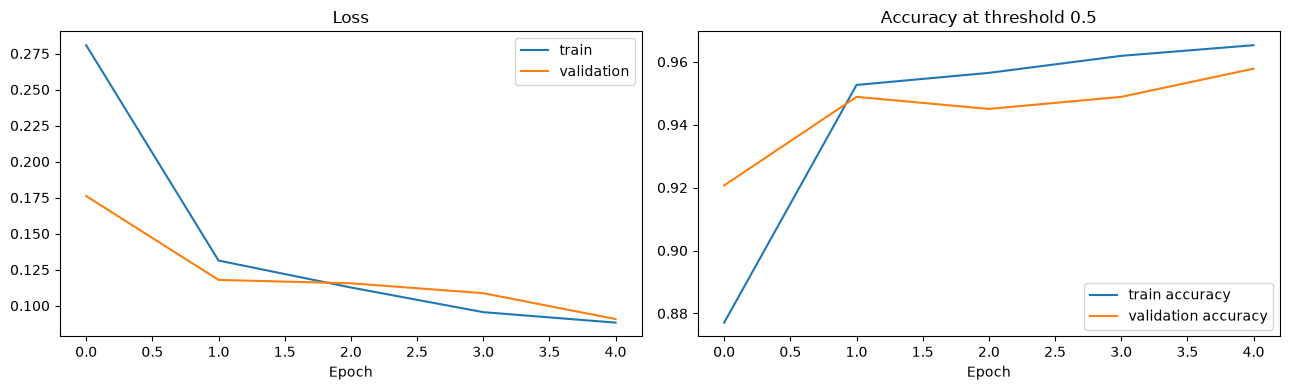

,accuracy_at_0_5,loss,pr_auc,precision_at_0_5,recall_at_0_5,roc_auc,val_accuracy_at_0_5,val_loss,val_pr_auc,val_precision_at_0_5,val_recall_at_0_5,val_roc_auc,learning_rate
0,0.877086,0.280782,0.984421,0.959396,0.870850,0.957316,0.920716,0.176114,1.0,1.0,0.920716,0.0,0.001
1,0.952639,0.131328,0.996902,0.989487,0.946086,0.990960,0.948849,0.117895,1.0,1.0,0.948849,0.0,0.001
2,0.956473,0.112617,0.997519,0.989854,0.950960,0.992804,0.945013,0.115536,1.0,1.0,0.945013,0.0,0.001
3,0.961885,0.095508,0.998183,0.990548,0.957661,0.994626,0.948849,0.108663,1.0,1.0,0.948849,0.0,0.001
4,0.965268,0.088236,0.998420,0.991826,0.961011,0.995285,0.957801,0.090758,1.0,1.0,0.957801,0.0,0.001


In [10]:
# Plot learning curves. Large divergence between train and validation curves can suggest overfitting.
history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["loss"], label="train")
axes[0].plot(history_df["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history_df.get("accuracy_at_0_5", []), label="train accuracy")
axes[1].plot(history_df.get("val_accuracy_at_0_5", []), label="validation accuracy")
axes[1].set_title("Accuracy at threshold 0.5")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()
display(history_df.tail())

## 9. Optional fine-tuning (skip on a slow computer)

Fine-tuning can sometimes improve a pretrained model, but it also increases compute and overfitting risk. The default is **off**. If you enable it, unfreeze only the final part of the backbone and use a much smaller learning rate. Batch-normalization layers remain frozen for stability.

After fine-tuning, threshold selection and final evaluation below will use the updated model.

In [11]:
# Set to True only if you want to try a second training phase.
RUN_FINE_TUNING = False
FINE_TUNE_EPOCHS = 3

if RUN_FINE_TUNING:
    base_model.trainable = True
    # Freeze earlier layers; adapt only a small final section.
    for layer in base_model.layers[:-30]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy_at_0_5"),
            keras.metrics.Precision(name="precision_at_0_5"),
            keras.metrics.Recall(name="recall_at_0_5"),
            keras.metrics.AUC(name="roc_auc", curve="ROC"),
            keras.metrics.AUC(name="pr_auc", curve="PR"),
        ],
    )
    fine_tune_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=1, min_lr=1e-7, verbose=1
        ),
    ]
    fine_tune_history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINE_TUNE_EPOCHS,
        class_weight=class_weight,
        callbacks=fine_tune_callbacks,
        verbose=1,
    )
else:
    print("Skipping fine-tuning. The frozen-backbone model will be evaluated.")

Skipping fine-tuning. The frozen-backbone model will be evaluated.


## 10. Select a recall-oriented threshold using validation data only

A 0.5 threshold is just a convention, not a medically meaningful cutoff. We choose an *educational* threshold from validation predictions by asking for the highest threshold that still reaches a target validation recall (default 0.95). A higher threshold generally reduces false positives but can increase false negatives.

This target is **not** a clinical requirement. On a small or unrepresentative validation set, the selected threshold can be unstable. If the target can be met only by labelling nearly every image `PNEUMONIA`, that trade-off must be shown rather than hidden. The final test set is not used to choose the threshold.

In [12]:
def collect_binary_labels(dataset):
    return np.concatenate([y.numpy().ravel().astype(int) for _, y in dataset])

def collect_scores(model, dataset):
    return model.predict(dataset, verbose=1).ravel().astype(float)

def confusion_metrics(y_true, scores, threshold=0.5):
    y_pred = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_pneumonia": precision_score(y_true, y_pred, zero_division=0),
        "recall_sensitivity_pneumonia": recall_score(y_true, y_pred, zero_division=0),
        "specificity_normal": tn / (tn + fp) if (tn + fp) else float("nan"),
        "f1_pneumonia": f1_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "n": int(len(y_true)),
    }

val_y = collect_binary_labels(val_ds)
val_scores = collect_scores(model, val_ds)

# Consider thresholds at each observed score, plus 0.0. Highest viable threshold maximizes
# specificity among these score cutoffs while meeting the chosen validation recall target.
threshold_candidates = np.unique(np.concatenate(([0.0], val_scores)))
viable = []
for threshold in threshold_candidates:
    metrics = confusion_metrics(val_y, val_scores, float(threshold))
    if metrics["recall_sensitivity_pneumonia"] >= TARGET_RECALL:
        viable.append((float(threshold), metrics))

if not viable:
    # Defensive fallback; with a non-empty positive class, threshold=0 predicts all positive.
    selected_threshold = 0.0
    print("Warning: no threshold met the requested target; fallback threshold 0.0 predicts every image positive.")
else:
    selected_threshold = max(viable, key=lambda item: item[0])[0]

val_metrics_at_05 = confusion_metrics(val_y, val_scores, 0.5)
val_metrics_selected = confusion_metrics(val_y, val_scores, selected_threshold)
print(f"Educational target validation recall: {TARGET_RECALL:.3f}")
print(f"Selected threshold: {selected_threshold:.6f}")
print("Validation metrics at 0.5:")
display(pd.DataFrame([val_metrics_at_05]))
print("Validation metrics at selected threshold:")
display(pd.DataFrame([val_metrics_selected]))

if val_metrics_selected["specificity_normal"] < 0.2:
    warnings.warn("Very low validation specificity: the recall target may be achieved by predicting many NORMAL images as PNEUMONIA.")
if val_metrics_selected["recall_sensitivity_pneumonia"] < TARGET_RECALL:
    warnings.warn("Requested validation recall target was not reached. Do not hide this limitation.")

49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step


c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaco

Educational target validation recall: 0.950
Selected threshold: 0.550954
Validation metrics at 0.5:


c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred con

,threshold,accuracy,precision_pneumonia,recall_sensitivity_pneumonia,specificity_normal,f1_pneumonia,balanced_accuracy,TN,FP,FN,TP,n
0,0.5,0.957801,1.0,0.957801,NaN,0.978445,0.957801,0,0,33,749,782


Validation metrics at selected threshold:


,threshold,accuracy,precision_pneumonia,recall_sensitivity_pneumonia,specificity_normal,f1_pneumonia,balanced_accuracy,TN,FP,FN,TP,n
0,0.550954,0.950128,1.0,0.950128,NaN,0.974426,0.950128,0,0,39,743,782


## 11. Final test-set evaluation (one time after threshold selection)

The test set is now evaluated using the threshold selected on the validation split. Report the confusion matrix explicitly. **False negatives (FN)** are images labelled `PNEUMONIA` that the model predicts as `NORMAL`; these are the errors this project asks us to examine closely.

Even high recall here does not establish clinical safety. The test set may be small, may share dataset-specific shortcuts, and does not represent deployment conditions.

In [13]:
test_y = collect_binary_labels(test_ds)
test_scores = collect_scores(model, test_ds)

test_metrics_05 = confusion_metrics(test_y, test_scores, 0.5)
test_metrics_selected = confusion_metrics(test_y, test_scores, selected_threshold)
print("Test-set metrics at the default 0.5 threshold:")
display(pd.DataFrame([test_metrics_05]))
print("Test-set metrics at the validation-selected threshold:")
display(pd.DataFrame([test_metrics_selected]))

print("Classification report at the validation-selected threshold:")
test_pred = (test_scores >= selected_threshold).astype(int)
print(classification_report(
    test_y,
    test_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    digits=3,
    zero_division=0,
))
print("Test ROC-AUC (ranking metric, not calibration):", round(roc_auc_score(test_y, test_scores), 4))
print("Test average precision / PR summary:", round(average_precision_score(test_y, test_scores), 4))

39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step
Test-set metrics at the default 0.5 threshold:


,threshold,accuracy,precision_pneumonia,recall_sensitivity_pneumonia,specificity_normal,f1_pneumonia,balanced_accuracy,TN,FP,FN,TP,n
0,0.5,0.849359,0.812236,0.987179,0.619658,0.891204,0.803419,145,89,5,385,624


Test-set metrics at the validation-selected threshold:


,threshold,accuracy,precision_pneumonia,recall_sensitivity_pneumonia,specificity_normal,f1_pneumonia,balanced_accuracy,TN,FP,FN,TP,n
0,0.550954,0.854167,0.820128,0.982051,0.641026,0.893816,0.811538,150,84,7,383,624


Classification report at the validation-selected threshold:
              precision    recall  f1-score   support

      NORMAL      0.955     0.641     0.767       234
   PNEUMONIA      0.820     0.982     0.894       390

    accuracy                          0.854       624
   macro avg      0.888     0.812     0.831       624
weighted avg      0.871     0.854     0.846       624

Test ROC-AUC (ranking metric, not calibration): 0.9634
Test average precision / PR summary: 0.9755


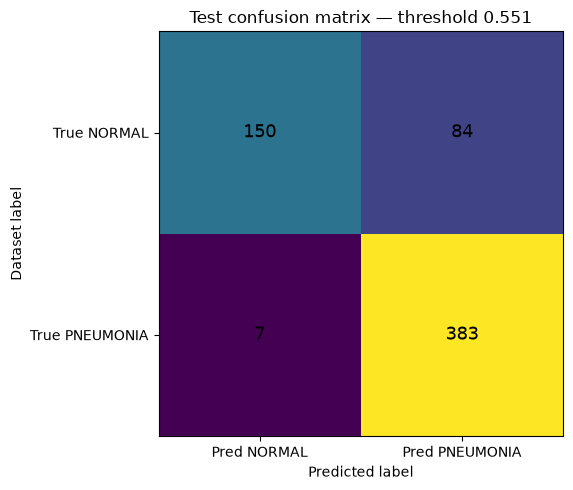

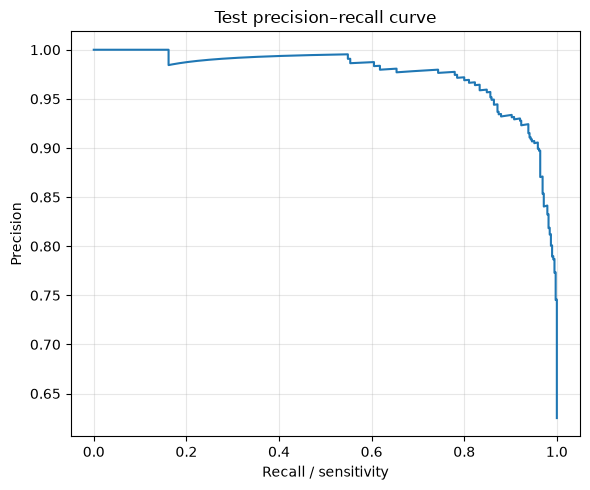

In [14]:
# Confusion matrix: rows = true class, columns = predicted class.
cm = confusion_matrix(test_y, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Pred NORMAL", "Pred PNEUMONIA"])
ax.set_yticks([0, 1], labels=["True NORMAL", "True PNEUMONIA"])
ax.set_title(f"Test confusion matrix — threshold {selected_threshold:.3f}")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center", fontsize=13)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Dataset label")
plt.tight_layout()
plt.show()

# Precision–recall curve on the test set (the chosen threshold is still validation-derived).
precision_vals, recall_vals, _ = precision_recall_curve(test_y, test_scores)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_vals, precision_vals)
ax.set_xlabel("Recall / sensitivity")
ax.set_ylabel("Precision")
ax.set_title("Test precision–recall curve")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. False-negative analysis (required project deliverable)

We identify false negatives at the validation-selected threshold, inspect their images, and list model scores. This is a structured error review—not an attempt to diagnose the images. Reasons an error may occur include subtle findings, image quality, an atypical presentation, an incorrect dataset label, class imbalance, domain shift, or the model focusing on irrelevant dataset artifacts. Do not infer the true cause from a few examples alone.

In [15]:
# The test dataset was created with shuffle=False and explicit class order. Rebuild the matching
# ordered path list from the same folders so each score can be connected to its source image.
test_ordered_paths = [
    p for class_name in CLASS_NAMES
    for p in sorted(
        q for q in (TEST_DIR / class_name).rglob("*")
        if q.is_file() and q.suffix.lower() in IMAGE_EXTENSIONS
    )
]

if len(test_ordered_paths) != len(test_y) or len(test_y) != len(test_scores):
    raise RuntimeError(
        "Path/label/score count mismatch. Stop before interpreting example paths; inspect the dataset loader order."
    )

error_df = pd.DataFrame({
    "path": [str(p) for p in test_ordered_paths],
    "true_label": test_y,
    "true_class": [CLASS_NAMES[int(y)] for y in test_y],
    "pneumonia_class_score": test_scores,
    "predicted_label": test_pred,
    "predicted_class": [CLASS_NAMES[int(y)] for y in test_pred],
})
error_df["error_type"] = np.select(
    [
        (error_df.true_label == 1) & (error_df.predicted_label == 0),
        (error_df.true_label == 0) & (error_df.predicted_label == 1),
    ],
    ["FALSE NEGATIVE", "FALSE POSITIVE"],
    default="CORRECT",
)
false_negatives = error_df[error_df.error_type == "FALSE NEGATIVE"].sort_values("pneumonia_class_score")
false_positives = error_df[error_df.error_type == "FALSE POSITIVE"].sort_values("pneumonia_class_score", ascending=False)

print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))
display(false_negatives.head(20).reset_index(drop=True))

False negatives: 7
False positives: 84


,path,true_label,true_class,pneumonia_class_score,predicted_label,predicted_class,error_type
0,C:\Users\Puneeth\Downloads\chest_xray\test\PNE...,1,PNEUMONIA,0.193807,0,NORMAL,FALSE NEGATIVE
1,C:\Users\Puneeth\Downloads\chest_xray\test\PNE...,1,PNEUMONIA,0.308105,0,NORMAL,FALSE NEGATIVE
2,C:\Users\Puneeth\Downloads\chest_xray\test\PNE...,1,PNEUMONIA,0.379264,0,NORMAL,FALSE NEGATIVE
3,C:\Users\Puneeth\Downloads\chest_xray\test\PNE...,1,PNEUMONIA,0.404057,0,NORMAL,FALSE NEGATIVE
4,C:\Users\Puneeth\Downloads\chest_xray\test\PNE...,1,PNEUMONIA,0.447436,0,NORMAL,FALSE NEGATIVE
5,C:\Users\Puneeth\Downloads\chest_xray\test\PNE...,1,PNEUMONIA,0.506032,0,NORMAL,FALSE NEGATIVE
6,C:\Users\Puneeth\Downloads\chest_xray\test\PNE...,1,PNEUMONIA,0.541679,0,NORMAL,FALSE NEGATIVE


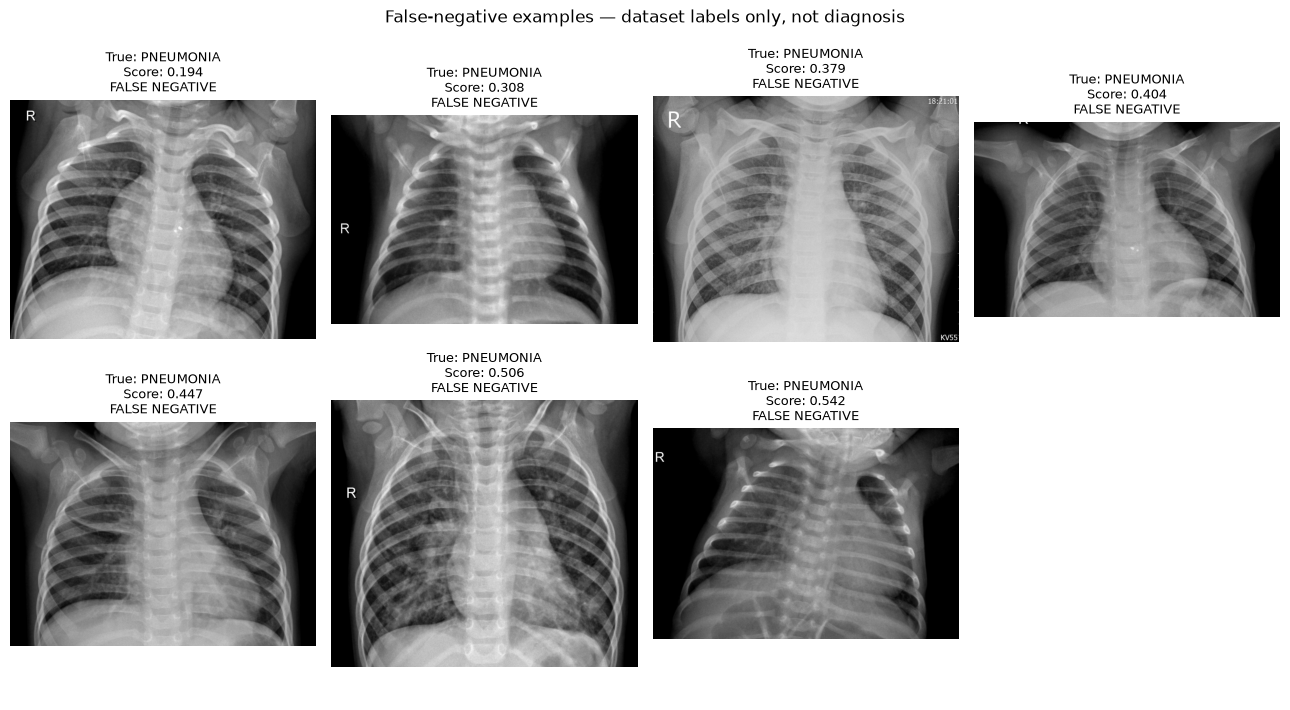

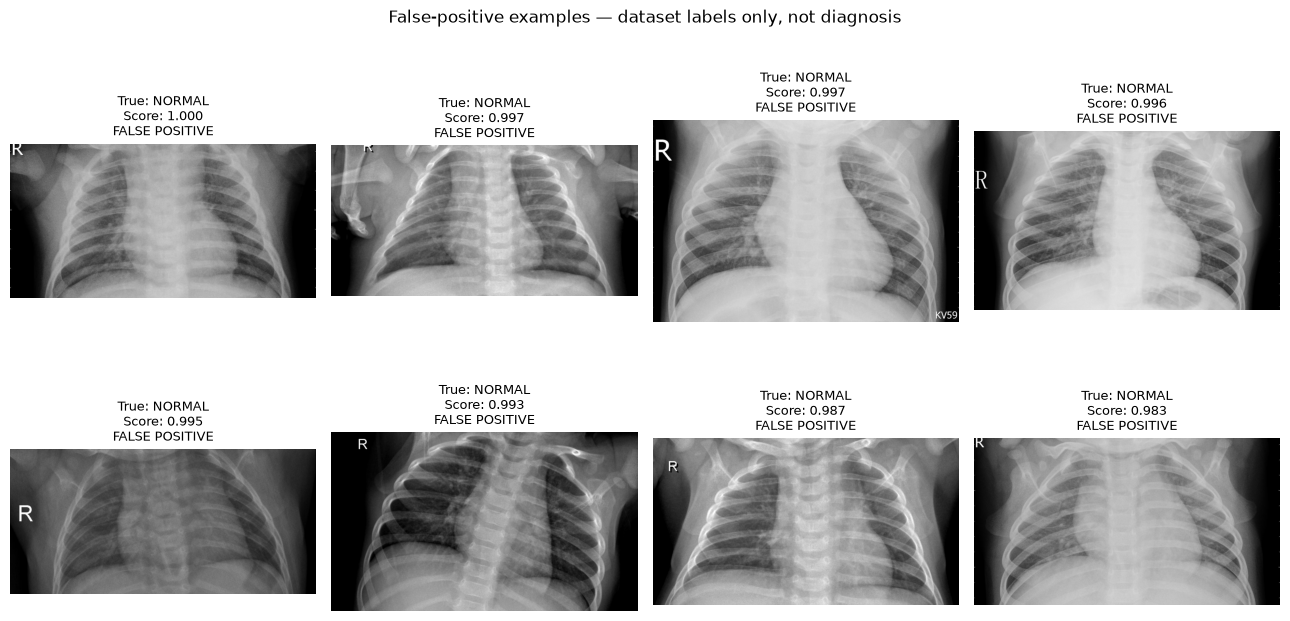

False-negative analysis checklist:
1. Inspect image quality and whether the label may need expert review.
2. Look for acquisition/source patterns or duplicate-like images across splits.
3. Check whether errors cluster by available metadata (age/site/scanner); metadata may be absent.
4. Record the error without claiming the model has found or missed a clinical diagnosis.


In [16]:
def display_error_examples(frame, title, max_images=8):
    if frame.empty:
        print(f"No examples in category: {title}")
        return
    shown = frame.head(max_images)
    ncols = 4
    nrows = int(np.ceil(len(shown) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.6 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, (_, row) in zip(axes, shown.iterrows()):
        try:
            with Image.open(row["path"]) as img:
                ax.imshow(img.convert("RGB"), cmap="gray")
            ax.set_title(
                f"True: {row['true_class']}\nScore: {row['pneumonia_class_score']:.3f}\n{row['error_type']}",
                fontsize=9,
            )
        except Exception as exc:
            ax.set_title(f"Could not load image: {exc}")
    fig.suptitle(title + " — dataset labels only, not diagnosis")
    plt.tight_layout()
    plt.show()

display_error_examples(false_negatives, "False-negative examples", max_images=8)
display_error_examples(false_positives, "False-positive examples", max_images=8)

print("False-negative analysis checklist:")
print("1. Inspect image quality and whether the label may need expert review.")
print("2. Look for acquisition/source patterns or duplicate-like images across splits.")
print("3. Check whether errors cluster by available metadata (age/site/scanner); metadata may be absent.")
print("4. Record the error without claiming the model has found or missed a clinical diagnosis.")

## 13. Threshold trade-off table

The table below illustrates how sensitivity and specificity change as the threshold changes. It is a diagnostic analysis of model behaviour on the validation split—not a list of recommended medical cutoffs. Pick thresholds on validation data only; do not select the best-looking row from the test set.

In [17]:
threshold_rows = []
for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, selected_threshold, 0.60, 0.70, 0.80, 0.90]:
    threshold = float(np.clip(threshold, 0.0, 1.0))
    m = confusion_metrics(val_y, val_scores, threshold)
    threshold_rows.append(m)
threshold_table = pd.DataFrame(threshold_rows).drop_duplicates(subset=["threshold"]).sort_values("threshold")
display(threshold_table[[
    "threshold", "recall_sensitivity_pneumonia", "specificity_normal",
    "precision_pneumonia", "f1_pneumonia", "FN", "FP"
]].round(3))

c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\Puneeth\anaconda3\envs\tf_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred con

,threshold,recall_sensitivity_pneumonia,specificity_normal,precision_pneumonia,f1_pneumonia,FN,FP
0,0.100,0.992,NaN,1.0,0.996,6,0
1,0.200,0.992,NaN,1.0,0.996,6,0
2,0.300,0.983,NaN,1.0,0.992,13,0
3,0.400,0.977,NaN,1.0,0.988,18,0
4,0.500,0.958,NaN,1.0,0.978,33,0
5,0.551,0.950,NaN,1.0,0.974,39,0
6,0.600,0.946,NaN,1.0,0.972,42,0
7,0.700,0.932,NaN,1.0,0.965,53,0
8,0.800,0.912,NaN,1.0,0.954,69,0
9,0.900,0.879,NaN,1.0,0.935,95,0


## 14. Save the demo model and threshold metadata

This saves a reusable model and a JSON file describing the label order and the validation-selected threshold. Keep the disclaimer with any demo or app that uses these files. Do not package it as a clinical decision tool.

In [18]:
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = OUTPUT_DIR / "chest_xray_pneumonia_demo.keras"
METADATA_PATH = OUTPUT_DIR / "chest_xray_pneumonia_demo_metadata.json"

model.save(MODEL_PATH)
metadata = {
    "project": "Day 62 Chest X-ray Pneumonia Classifier — educational demo",
    "classes": {"0": "NORMAL", "1": "PNEUMONIA"},
    "image_size": list(IMAGE_SIZE),
    "input_color_mode": "RGB",
    "selected_threshold": float(selected_threshold),
    "threshold_selection": f"Validation split; highest observed-score threshold meeting target recall {TARGET_RECALL}",
    "validation_target_recall": float(TARGET_RECALL),
    "test_metrics_at_selected_threshold": {
        key: (float(value) if isinstance(value, (np.floating, float)) else int(value) if isinstance(value, (np.integer, int)) else value)
        for key, value in test_metrics_selected.items()
    },
    "medical_safety": "Educational demo only; not a medical device or clinically validated. Not for diagnosis, triage, treatment, or ruling out disease.",
    "dataset_source": "Kaggle Chest X-Ray Images (Pneumonia); consult dataset page and licence",
}
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", MODEL_PATH.resolve())
print("Saved metadata:", METADATA_PATH.resolve())

Saved model: C:\Users\Puneeth\Desktop\dev-studies\2026 07 13 ML learning\machine-learning-from-scratch\daily learning\Day62_Chest_XRay_Pneumonia_Classifier\artifacts\chest_xray_pneumonia_demo.keras
Saved metadata: C:\Users\Puneeth\Desktop\dev-studies\2026 07 13 ML learning\machine-learning-from-scratch\daily learning\Day62_Chest_XRay_Pneumonia_Classifier\artifacts\chest_xray_pneumonia_demo_metadata.json


## 15. Try one image (demo only)

Use an image from the public project dataset, not a real patient image. The output is a dataset-class score and label, not a calibrated probability of disease. A `NORMAL` class prediction must never be interpreted as “no pneumonia.”

In [19]:
def score_one_image(image_path, model=model, threshold=selected_threshold):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")
    img = keras.utils.load_img(image_path, target_size=IMAGE_SIZE, color_mode="rgb")
    arr = keras.utils.img_to_array(img).astype("float32")
    score = float(model.predict(np.expand_dims(arr, axis=0), verbose=0).ravel()[0])
    predicted_class = "PNEUMONIA" if score >= threshold else "NORMAL"
    print("Educational model output only — NOT a diagnosis.")
    print(f"Pneumonia-class score (not a calibrated clinical probability): {score:.4f}")
    print(f"Predicted dataset class at threshold {threshold:.4f}: {predicted_class}")
    print("Do not use this result to reassure, diagnose, triage, or choose treatment for anyone.")
    return {"score": score, "predicted_dataset_class": predicted_class, "threshold": float(threshold)}

# Example: uncomment and replace with a public dataset image path.
# example_path = test_paths_by_class["PNEUMONIA"][0]
# score_one_image(example_path)

## 16. Portfolio model card (complete this before publishing)

Copy these fields into your README or project page. Report your actual metrics from this run—do not promise a particular accuracy/recall before running the notebook.

- **Project purpose:** Educational binary classification of images in a public chest-X-ray dataset.
- **Intended users:** Students/reviewers learning computer vision; not patients or clinicians for care decisions.
- **Data:** Public chest X-rays labelled `NORMAL` or `PNEUMONIA`; cite Kermany et al. (2018) and follow the dataset licence.
- **Model:** ImageNet-pretrained MobileNetV2 with a binary sigmoid head.
- **Input / output:** 224×224 RGB image; one pneumonia-class score and a thresholded dataset label.
- **Threshold policy:** Selected on the validation subset to explore a target recall; report the resulting precision and specificity too.
- **Evaluation:** Include held-out test confusion matrix, recall/sensitivity, specificity, precision, F1, ROC-AUC, average precision, and false-negative count.
- **Known risks:** Dataset shift, pediatric-only source population, class imbalance, imperfect labels, image/source leakage, shortcut learning, lack of calibration, threshold instability, and false negatives.
- **Clinical disclaimer:** Not for diagnosis, screening, triage, or treatment; normal-class output does not rule out disease.
- **Limitations of this run:** Add your TensorFlow version, hardware, epoch count, actual results, and any execution issues.

## 17. Reflection questions

1. Did the threshold chosen for high validation recall reduce specificity or precision? Quantify the trade-off.
2. How many false negatives appeared on the test set? What would be unsafe about reporting accuracy without FN count and recall?
3. Why must threshold selection happen on the validation set rather than repeatedly testing thresholds on the test set?
4. Could the model be using shortcuts (for example, markers, borders, source/site patterns, or image processing) rather than lung findings? What checks would you add?
5. What data and review would be required before anyone could contemplate clinical use? Discuss external, patient-level, prospective validation and clinical/regulatory oversight.

## 18. References

- Kermany, D. S. et al. (2018). *Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning*. Cell. <https://www.cell.com/cell/fulltext/S0092-8674(18)30154-5>
- Kaggle dataset page: *Chest X-Ray Images (Pneumonia)*. <https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia>
- Keras image loading documentation: <https://keras.io/api/data_loading/image/>
- FDA, Digital Health Policy Navigator — software that analyzes medical images may raise medical-device considerations depending on intended use: <https://www.fda.gov/medical-devices/digital-health-center-excellence/step-6-software-function-intended-provide-clinical-decision-support>

**Final reminder:** This is a computer-vision learning exercise, not clinical evidence. Never use the model to make decisions about a real person.